In [1]:
import pandas as pd
import os

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('../')

## Data

In [2]:
data = pd.read_csv('data/tweets.csv')
data.rename(columns={'tweet_text': 'text'}, inplace=True)
data.drop_duplicates(subset=['text'], inplace=True)
data = data.reset_index(drop=True)
label = 'cyberbullying_type'
text = 'text'
display(data[label].value_counts())

cyberbullying_type
religion               7995
age                    7992
ethnicity              7952
not_cyberbullying      7937
gender                 7898
other_cyberbullying    6243
Name: count, dtype: int64

46 017 твитов после дедупликации. Классы почти равны, кроме `other_cyberbullying`
(6 243 против ~8 000, перекос 1.28:1); сплит 80/20 стратифицирован: 36 813 / 9 204.

In [3]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

train, test = train_test_split(
    data, test_size=0.2, stratify=data[label], random_state=42
)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)
print(train.shape, test.shape)

(36813, 2) (9204, 2)


In [4]:
import re
import nltk
from nltk.corpus import stopwords

try:
    stop_words = set(stopwords.words('english'))
except LookupError:
    nltk.download('stopwords', quiet=True)
    stop_words = set(stopwords.words('english'))

def clean(text):
    text = text.lower()
    text = re.sub(r'http\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)
    text = re.sub(r'\brt\b', ' ', text)
    text = re.sub(r'#', '', text)
    return re.sub(r'\s+', ' ', text).strip()

def tokenize(text):
    tokens = re.findall(r"[a-z']+", clean(text))
    tokens = [t.strip("'") for t in tokens]
    return [t for t in tokens if len(t) >= 3 and t not in stop_words]

train[text].head(3).apply(tokenize)

0    [dumb, ass, nigger, let, fuck, aint, nothing, ...
1          [annie, worried, blondes, late, dummy, mkr]
2    [fuck, wit, dumb, ass, fuck, hit, nigger, face...
Name: text, dtype: object

## Vectorization

In [5]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

bow = CountVectorizer(stop_words='english', ngram_range=(1, 2), min_df=5, max_df=0.9)
tfidf = TfidfVectorizer(
    stop_words='english', ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True
)

X_train_bow = bow.fit_transform(train[text])
X_test_bow = bow.transform(test[text])
X_train_tfidf = tfidf.fit_transform(train[text])
X_test_tfidf = tfidf.transform(test[text])

def vec_stats(name, X):
    return {
        'vectorizer': name,
        'n_features': X.shape[1],
        'train_nnz': X.nnz,
        'density': X.nnz / (X.shape[0] * X.shape[1]),
    }

vec_df = pd.DataFrame([
    vec_stats('CountVectorizer', X_train_bow),
    vec_stats('TfidfVectorizer', X_train_tfidf),
])
display(vec_df.round(5))

,vectorizer,n_features,train_nnz,density
0,CountVectorizer,15385,489318,0.00086
1,TfidfVectorizer,15385,489318,0.00086


### n-gram ablation

In [6]:
ablation = []
for ngram_range in [(1, 1), (1, 2)]:
    vec = CountVectorizer(
        stop_words='english', ngram_range=ngram_range, min_df=5, max_df=0.9
    )
    X = vec.fit_transform(train[text])
    ablation.append({
        'ngram_range': str(ngram_range),
        'n_features': X.shape[1],
        'train_nnz': X.nnz,
        'density': X.nnz / (X.shape[0] * X.shape[1]),
    })

display(pd.DataFrame(ablation).round(5))

,ngram_range,n_features,train_nnz,density
0,"(1, 1)",8723,391902,0.00122
1,"(1, 2)",15385,489318,0.00086


Словарь 15 385 признаков (1–2-граммы, `min_df=5`); у BoW и TF-IDF размерность одна —
словарь общий, `fit` только на train, `transform` на test.

Классы почти сбалансированы; для SVM используется `class_weight='balanced'`.

In [7]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

nb = MultinomialNB(alpha=0.5)
svc = LinearSVC(class_weight='balanced', random_state=42)

nb.fit(X_train_tfidf, train[label])
svc.fit(X_train_tfidf, train[label])

nb_pred = nb.predict(X_test_tfidf)
svc_pred = svc.predict(X_test_tfidf)

Метрики — macro P/R/F1 и accuracy.

In [8]:
from sklearn.metrics import (
    precision_recall_fscore_support, accuracy_score,
    classification_report, confusion_matrix,
)

def get_scores(name, y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    return {
        'model': name,
        'precision': p,
        'recall': r,
        'f1': f1,
        'accuracy': accuracy_score(y_true, y_pred),
    }

results = pd.DataFrame([
    get_scores('MultinomialNB', test[label], nb_pred),
    get_scores('LinearSVC', test[label], svc_pred),
])
display(results.round(4))

best_name = results.sort_values('f1', ascending=False).iloc[0]['model']
best_pred = nb_pred if best_name == 'MultinomialNB' else svc_pred
print(best_name)
print(classification_report(test[label], best_pred, zero_division=0))

,model,precision,recall,f1,accuracy
0,MultinomialNB,0.7826,0.7879,0.7805,0.7987
1,LinearSVC,0.8387,0.8383,0.8384,0.8468


LinearSVC
                     precision    recall  f1-score   support

                age       0.96      0.97      0.97      1599
          ethnicity       0.97      0.97      0.97      1590
             gender       0.90      0.88      0.89      1580
  not_cyberbullying       0.64      0.64      0.64      1587
other_cyberbullying       0.59      0.62      0.60      1249
           religion       0.97      0.95      0.96      1599

           accuracy                           0.85      9204
          macro avg       0.84      0.84      0.84      9204
       weighted avg       0.85      0.85      0.85      9204



LinearSVC лучше NB (macro F1 0.838 / 0.781); accuracy 0.847 близка к macro F1 из-за
мягкого дисбаланса, но не показывает, какие классы проваливаются до 0.6.

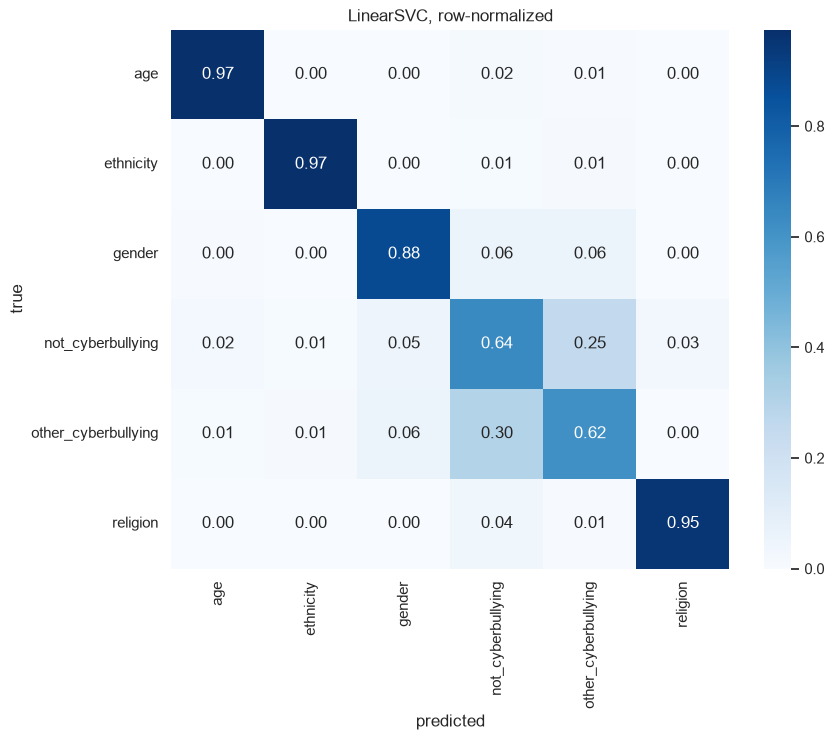

errors: 1410 (15.3%)
not -> other: 0.2514177693761815
other -> not: 0.3026421136909528


,age,ethnicity,gender,not_cyberbullying,other_cyberbullying,religion
age,1558,4,1,25,9,2
ethnicity,3,1547,5,13,20,2
gender,7,3,1384,89,91,6
not_cyberbullying,36,18,81,1010,399,43
other_cyberbullying,14,15,71,378,769,2
religion,2,0,2,61,8,1526


In [9]:
labels_sorted = sorted(test[label].unique())
cm = confusion_matrix(test[label], best_pred, labels=labels_sorted, normalize='true')
cm_counts = pd.DataFrame(
    confusion_matrix(test[label], best_pred, labels=labels_sorted),
    index=labels_sorted, columns=labels_sorted,
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    pd.DataFrame(cm, index=labels_sorted, columns=labels_sorted),
    annot=True, fmt='.2f', cmap='Blues',
)
plt.xlabel('predicted')
plt.ylabel('true')
plt.title(f'{best_name}, row-normalized')
plt.show()

err_mask = test[label].values != best_pred
print('errors:', int(err_mask.sum()), f'({err_mask.mean():.1%})')
print('not -> other:', cm[labels_sorted.index('not_cyberbullying'), labels_sorted.index('other_cyberbullying')])
print('other -> not:', cm[labels_sorted.index('other_cyberbullying'), labels_sorted.index('not_cyberbullying')])
display(cm_counts)

Основная граница ошибок — not ↔ other (25.1% / 30.3%); age, ethnicity и religion
почти не путаются.

### Error analysis

Пять ошибок лучшей модели на тесте; пары (истинный класс, предсказание) не повторяются.

In [10]:
mask = test[label].values != best_pred
err = test.loc[mask, [label, text]].copy()
err['pred'] = best_pred[mask]

# по одному примеру на самый частый тип ошибки для пяти из шести классов
pairs = (
    err.groupby([label, 'pred']).size().reset_index(name='n')
    .sort_values('n', ascending=False).drop_duplicates(label).head(5)
)
cand = err[err[text].str.len().between(40, 300)]
rows = []
for _, r in pairs.iterrows():
    sub = cand[(cand[label] == r[label]) & (cand['pred'] == r['pred'])]
    if sub.empty:
        sub = err[(err[label] == r[label]) & (err['pred'] == r['pred'])]
    rows.append(sub.sample(1, random_state=42))
err5 = pd.concat(rows)
err5['text'] = err5[text].str.slice(0, 400)
display(err5[[label, 'pred', text]])
for _, r in err5.iterrows():
    print(f"[{r[label]} -> {r['pred']}] {r[text]}")

,cyberbullying_type,pred,text
6622,not_cyberbullying,other_cyberbullying,"These guys finally exhausted themselves. Yay, ..."
393,other_cyberbullying,not_cyberbullying,@6ft8_Dwarf someone in my hometown i managed t...
4398,gender,other_cyberbullying,@Miikito_x3: Toto means ass or vagina?I think ...
0,religion,not_cyberbullying,@dankmtl Load of BS. Their numbers fell steadi...
2862,age,not_cyberbullying,When you are in pain and have zero tools to he...


[not_cyberbullying -> other_cyberbullying] These guys finally exhausted themselves. Yay, quiet time. http://t.co/dpPo0xMiDu
[other_cyberbullying -> not_cyberbullying] @6ft8_Dwarf someone in my hometown i managed to bully into spending time with me lol.  It starts at 8, i thought that was quite late
[gender -> other_cyberbullying] @Miikito_x3: Toto means ass or vagina?I think pussy cause toto santi is like nasty pussy
[religion -> not_cyberbullying] @dankmtl Load of BS. Their numbers fell steadily since then. And you're still too stupid to see that doesn't change ratios.
[age -> not_cyberbullying] When you are in pain and have zero tools to heal, you harm and inflict pain on others. You become a bully in the classroom, on social media and the boardroom. This is why self-awareness and mindfulness is so important for schools to incorporate within their curriculums.


Пять ошибок лучшей модели, по одной на самый частый тип для пяти из шести классов:
модель опирается на явные оскорбления и ломается на неявной травле и шуме разметки.

## Inverted index

Индекс строится по всему дедуплицированному корпусу; документ — один твит.

In [11]:
from collections import Counter
import numpy as np

def build_index(texts):
    inverted_index = {}
    bags = []
    doc_len = np.zeros(len(texts), dtype=int)
    df = Counter()

    for i, t in enumerate(texts):
        tokens = tokenize(t)
        bag = Counter(tokens)
        bags.append(bag)
        doc_len[i] = len(tokens)
        for word in bag:
            inverted_index.setdefault(word, []).append(i)
            df[word] += 1

    inverted_index = {word: sorted(ids) for word, ids in inverted_index.items()}
    return inverted_index, bags, doc_len, dict(df)

inverted_index, bags, doc_len, df = build_index(data[text])
N = len(bags)
print('N docs:', N)
print('vocabulary:', len(inverted_index))
print('avg doc length:', round(float(doc_len.mean()), 2))
print("posting 'bully':", inverted_index.get('bully', [])[:20])

N docs: 46017
vocabulary: 41173
avg doc length: 12.47
posting 'bully': [6, 11, 18, 49, 56, 62, 72, 91, 140, 164, 167, 218, 225, 281, 297, 298, 316, 346, 384, 448]


46 017 документов, 41 173 уникальных слова, средняя длина 12.47 токена после стоп-слов.

## BM25


In [12]:
import math

def bm25_search(query, topn=5, k1=1.5, b=0.75):
    terms = list(dict.fromkeys(tokenize(query)))
    scores = np.zeros(N)
    avgdl = doc_len.mean()

    for term in terms:
        ids = inverted_index.get(term)
        if not ids:
            continue
        idf = math.log((N - df[term] + 0.5) / (df[term] + 0.5) + 1)
        for i in ids:
            tf = bags[i][term]
            scores[i] += idf * tf * (k1 + 1) / (
                tf + k1 * (1 - b + b * doc_len[i] / avgdl)
            )

    candidates = np.flatnonzero(scores > 0)
    if len(candidates) == 0:
        return pd.DataFrame(columns=['doc_id', 'score', 'label', 'text'])
    top = candidates[np.argsort(scores[candidates])[::-1][:topn]]
    return pd.DataFrame({
        'doc_id': top,
        'score': scores[top],
        'label': data[label].values[top],
        'text': data[text].str.slice(0, 180).values[top],
    })

In [13]:
for query in ['school bully', 'islam terrorism', 'women kitchen']:
    print(query)
    display(bm25_search(query))

school bully


,doc_id,score,label,text
0,32054,7.230260,age,UR A BULLY A HIGH SCHOOL BULLY
1,32477,6.992059,age,amber is a high school bully high school fucki...
2,33451,6.992059,age,"I used to wear specks in school, a school bull..."
3,31638,6.960405,age,The bully at school
4,36482,6.960405,age,Wasn't she the school bully?


islam terrorism


,doc_id,score,label,text
0,19217,12.323677,religion,All the world are protesting islamic terrorism...
1,18913,10.510713,religion,"@zakirnaikirf Fuck Allah, the phony god of Isl..."
2,20021,10.206752,religion,He is a so called Muslim. Islam never promote ...
3,21525,9.899825,religion,U r seeing Islam as islamphobic want to repres...
4,20303,9.874718,religion,Islamic terrorism..terrorism is only practised...


women kitchen


,doc_id,score,label,text
0,11159,11.882671,gender,RT @LOTRQuotes69: Why shouldn't women drive? B...
1,9569,11.392441,gender,"RT @ol_dirtymarco I'm not sexist, but I must a..."
2,11945,10.524081,gender,RT @jadeCFC_ Sounds like we've got a well good...
3,25137,10.137720,other_cyberbullying,All the Jeff fans....did you see how dickhead ...
4,1864,9.889415,not_cyberbullying,#NW My Kitchen Rules #MKR


`school bully` → age, `islam terrorism` → religion; в `women kitchen` BM25 цепляется
за `kitchen` (шоу «My Kitchen Rules») — семантики нет.

## LDA

На трейне сэмплируется по 1500 документов каждого класса; темы строятся по мешку
слов после `filter_extremes`.

dictionary size:

 3001


,k,coherence
0,2,0.2797
1,3,0.4984
2,4,0.4914
3,5,0.4648
4,6,0.4830
5,7,0.4431
6,8,0.4277
7,9,0.4228
8,10,0.4118
9,11,0.4200


best k: 3


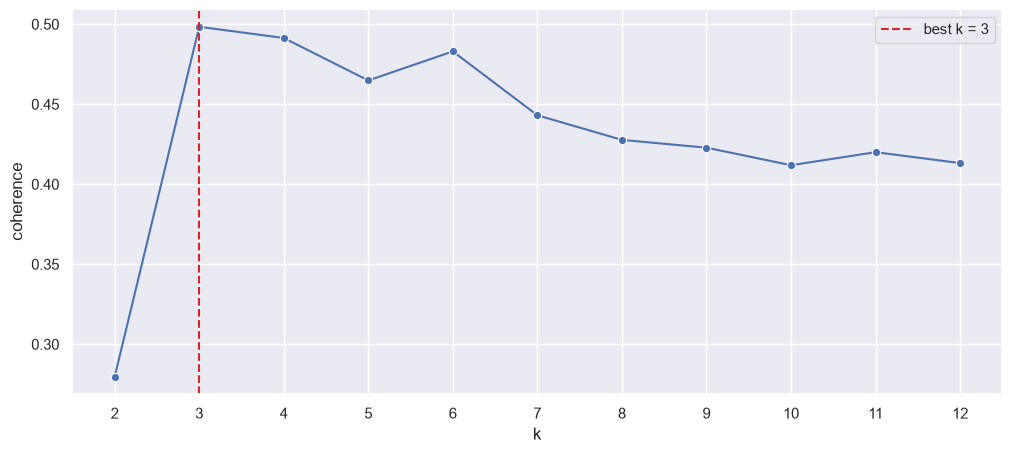

In [14]:
from gensim.corpora import Dictionary
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel

lda_sample = train.groupby(label, group_keys=False).sample(1500, random_state=42)
lda_tokens = lda_sample[text].apply(tokenize).tolist()

dictionary = Dictionary(lda_tokens)
dictionary.filter_extremes(no_below=5, no_above=0.5)
print('dictionary size:', len(dictionary))
lda_corpus = [dictionary.doc2bow(tokens) for tokens in lda_tokens]

coherence_rows = []
lda_models = {}
for k in range(2, 13):
    lda = LdaModel(
        corpus=lda_corpus, id2word=dictionary, num_topics=k,
        passes=10, random_state=42, chunksize=2000, iterations=100,
    )
    score = CoherenceModel(
        model=lda, texts=lda_tokens, dictionary=dictionary, coherence='c_v', processes=1, topn=20
    ).get_coherence()
    coherence_rows.append({'k': k, 'coherence': score})
    lda_models[k] = lda

coherence_df = pd.DataFrame(coherence_rows)
best_k = int(coherence_df.loc[coherence_df['coherence'].idxmax(), 'k'])
best_lda = lda_models[best_k]

display(coherence_df.round(4))
plt.figure(figsize=(12, 5))
sns.lineplot(data=coherence_df, x='k', y='coherence', marker='o')
plt.axvline(best_k, color='tab:red', linestyle='--', label=f'best k = {best_k}')
plt.xticks(range(2, 13))
plt.legend()
print('best k:', best_k)

Coherence по top-20 словам, K=2..12; максимум 0.498 при K=3, после K=6 значения ниже.

## Topics

Топ-10 слов лучшей модели; вес — вероятность слова в теме.

In [15]:
topic_rows = []
for topic_id in range(best_lda.num_topics):
    words = [
        f'{word}:{prob:.3f}'
        for word, prob in best_lda.show_topic(topic_id, topn=10)
    ]
    topic_rows.append({'topic': topic_id, 'top_words': ', '.join(words)})

topics_df = pd.DataFrame(topic_rows)
display(topics_df)
for _, row in topics_df.iterrows():
    print(f"topic {row['topic']}: {row['top_words']}")

,topic,top_words
0,0,"school:0.026, rape:0.020, gay:0.018, like:0.01..."
1,1,"fuck:0.039, dumb:0.035, nigger:0.027, mkr:0.02..."
2,2,"muslims:0.023, muslim:0.022, idiot:0.018, chri..."


topic 0: school:0.026, rape:0.020, gay:0.018, like:0.016, high:0.015, bullied:0.015, jokes:0.014, bully:0.014, people:0.010, one:0.009
topic 1: fuck:0.039, dumb:0.035, nigger:0.027, mkr:0.023, ass:0.022, fucking:0.016, bitch:0.016, call:0.015, like:0.013, white:0.013
topic 2: muslims:0.023, muslim:0.022, idiot:0.018, christian:0.015, right:0.013, idiots:0.013, islamic:0.012, terrorism:0.011, people:0.011, woman:0.011


## Выводы

- LinearSVC (macro F1 0.838) лучше NB; главная граница ошибок — not ↔ other (55% ошибок).
- BM25 хорош на точных лексических запросах, но не понимает семантику (`kitchen` → шоу «My Kitchen Rules»).
- LDA: лучший K=3 по coherence (0.498); темы шире, чем 6 классов разметки.